# Tedence Data Scientist Technical Assignment

**Candidate:** Tal Dor \
**Position:** Data Scientist \
**Interviewer:** Matan Orr \
**Date:** November 21, 2026 \
**Deadline:** December 1, 2026

---

## Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-whitegrid')

# File paths
EMF_PATH = '../data/emf_readings.parquet'
CGM_PATH = '../data/cgm_reference.xlsx'

---
## 1. Data Loading

Load both datasets and display basic info.

In [2]:
# Load EMF data
emf_df = pd.read_parquet(EMF_PATH)
cgm_df = pd.read_excel(CGM_PATH)

# Validate the supplied datasets before selecting a patient/session.
keys = ["patient_id", "session_id", "timestamp"]
validation_rows = []
for name, frame in [("EMF", emf_df), ("CGM", cgm_df)]:
    validation_rows.append({
        "Dataset": name, "Rows": len(frame), "Columns": len(frame.columns),
        "Start": frame["timestamp"].min(), "End": frame["timestamp"].max(),
        "Duplicate keys": int(frame.duplicated(keys).sum()),
        "Missing key values": int(frame[keys].isna().any(axis=1).sum()),
        "Time ordered within sessions": all(
            group["timestamp"].is_monotonic_increasing
            for _, group in frame.groupby(["patient_id", "session_id"])
        ),
    })
# Require exactly one complete patient/session in each dataset before analysis.
session_columns = ["patient_id", "session_id"]
for name, frame in [("EMF", emf_df), ("CGM", cgm_df)]:
    if frame[keys].isna().any(axis=1).any():
        raise ValueError(f"{name} contains missing identifiers or timestamps; resolve them before analysis.")
    if len(frame[session_columns].drop_duplicates()) != 1:
        raise ValueError(f"{name} must contain exactly one patient/session; select one explicitly before analysis.")
emf_session = tuple(emf_df[session_columns].iloc[0])
cgm_session = tuple(cgm_df[session_columns].iloc[0])
if emf_session != cgm_session:
    raise ValueError("EMF and CGM must refer to the same patient/session.")
PATIENT_ID, SESSION_ID = emf_session

emf_df.info()
display(emf_df.groupby(["patient_id", "session_id"]).size().rename("Readings"))

start = emf_df["timestamp"].min()
end = emf_df["timestamp"].max()
print("First timestamp:", start)
print("Last timestamp:", end)
print("Time between first and last readings:", end - start)

# Count the gaps between consecutive readings
time_gaps = emf_df["timestamp"].sort_values().diff()
print("\nTime gaps:")
display(time_gaps.value_counts().rename("Count"))

display(emf_df)

<class 'pandas.DataFrame'>
RangeIndex: 3600 entries, 0 to 3599
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   timestamp       3600 non-null   datetime64[ns]
 1   patient_id      3600 non-null   str           
 2   session_id      3600 non-null   str           
 3   Liver1_pT       3600 non-null   float64       
 4   Liver2_pT       3600 non-null   float64       
 5   Background1_pT  3600 non-null   float64       
 6   Arm1_pT         3477 non-null   float64       
 7   Chest1_pT       3600 non-null   float64       
dtypes: datetime64[ns](1), float64(5), str(2)
memory usage: 253.3 KB


patient_id  session_id
P001        S001          3600
Name: Readings, dtype: int64

First timestamp: 2025-01-15 09:00:00
Last timestamp: 2025-01-15 09:59:59
Time between first and last readings: 0 days 00:59:59

Time gaps:


timestamp
0 days 00:00:01    3599
Name: Count, dtype: int64

,timestamp,patient_id,session_id,Liver1_pT,Liver2_pT,Background1_pT,Arm1_pT,Chest1_pT
0,2025-01-15 09:00:00,P001,S001,-5.8923,-2.9292,-2.8550,2.6378,0.8771
1,2025-01-15 09:00:01,P001,S001,-6.0874,-4.8913,-3.6009,5.3747,1.9522
2,2025-01-15 09:00:02,P001,S001,-5.5874,-2.6362,-3.5693,5.9587,2.8572
3,2025-01-15 09:00:03,P001,S001,-5.6786,-2.9340,-2.0728,2.2244,2.0511
4,2025-01-15 09:00:04,P001,S001,-5.1934,-2.4981,-1.7426,4.6263,-1.6575
...,...,...,...,...,...,...,...,...
3595,2025-01-15 09:59:55,P001,S001,0.8984,-7.4931,3.2923,-4.7900,-6.5788
3596,2025-01-15 09:59:56,P001,S001,-0.0614,-3.0279,3.9818,-4.5566,-9.2589
3597,2025-01-15 09:59:57,P001,S001,0.2027,-2.3904,4.9302,-5.5853,-4.0411
3598,2025-01-15 09:59:58,P001,S001,-0.4115,-3.1215,4.2880,-5.4877,-5.3842


*Notes:*
The background sensor serves as a control, so I’d place Background1_pT at the end of the table to distinguish it from the body sensor channels.

In [3]:

emf_sorted = emf_df.sort_values("timestamp").copy()
emf_values = emf_sorted.filter(regex=r"_pT$")

desc = pd.DataFrame({
    "Missing (%)": 100 * emf_values.isna().mean(),
    "Mean (pT)": emf_values.mean(),
    "Median (pT)": emf_values.median(),
    "Std dev (pT)": emf_values.std(),
    "IQR (pT)": emf_values.quantile(0.75) - emf_values.quantile(0.25),
    "Min (pT)": emf_values.min(),
    "Max (pT)": emf_values.max(),
    "Range (pT)": emf_values.max() - emf_values.min(),
}).rename_axis("Channel")

# Place the background control after the body sensors.
channel_order = [name for name in desc.index if name != "Background1_pT"]
channel_order.append("Background1_pT")

print("EMF signal summary by sensor")
print(desc.loc[channel_order].to_string(float_format="{:.2f}".format))

EMF signal summary by sensor
                Missing (%)  Mean (pT)  Median (pT)  Std dev (pT)  IQR (pT)  Min (pT)  Max (pT)  Range (pT)
Channel                                                                                                    
Liver1_pT              0.00      -0.00         0.23          3.00      3.52     -7.26      7.47       14.73
Liver2_pT              0.00       0.00         0.08          3.00      4.25     -9.82      9.00       18.82
Arm1_pT                3.42      -0.01        -0.45          3.00      3.27     -8.12      9.27       17.39
Chest1_pT              0.00       0.00         0.00          3.00      3.93    -10.09      7.82       17.91
Background1_pT         0.00       0.01        -0.70          3.16      4.22    -26.09     37.93       64.02


In [4]:
# Inspect the CGM data loaded and validated above.

cgm_df.info()

# Count readings for each patient and session
session_counts = cgm_df.groupby(["patient_id", "session_id"]).size()
print("\nReadings per patient and session")
print(session_counts.reset_index(name="Readings").to_string(index=False))

# Check the interval between consecutive readings
cgm_gaps = cgm_df["timestamp"].sort_values().diff()
print("\nTime gaps between readings")
print(cgm_gaps.value_counts().to_string())

# Show the recorded values last
display(cgm_df)

<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   timestamp      60 non-null     datetime64[us]
 1   glucose_mg_dl  60 non-null     float64       
 2   patient_id     60 non-null     str           
 3   session_id     60 non-null     str           
dtypes: datetime64[us](1), float64(1), str(2)
memory usage: 2.5 KB

Readings per patient and session
patient_id session_id  Readings
      P001       S001        60

Time gaps between readings
timestamp
0 days 00:01:00    59


,timestamp,glucose_mg_dl,patient_id,session_id
0,2025-01-15 09:00:00,102.5,P001,S001
1,2025-01-15 09:01:00,100.1,P001,S001
2,2025-01-15 09:02:00,104.9,P001,S001
3,2025-01-15 09:03:00,110.1,P001,S001
4,2025-01-15 09:04:00,102.2,P001,S001
5,2025-01-15 09:05:00,103.2,P001,S001
6,2025-01-15 09:06:00,113.3,P001,S001
7,2025-01-15 09:07:00,110.6,P001,S001
8,2025-01-15 09:08:00,106.0,P001,S001
9,2025-01-15 09:09:00,113.1,P001,S001


In [5]:
# Show the validation results computed before analysis.
display(pd.DataFrame(validation_rows).set_index("Dataset"))

,Rows,Columns,Start,End,Duplicate keys,Missing key values,Time ordered within sessions
Dataset,,,,,,,
EMF,3600,8,2025-01-15 09:00:00,2025-01-15 09:59:59,0,0,True
CGM,60,4,2025-01-15 09:00:00,2025-01-15 09:59:00,0,0,True


In [6]:

glucose = cgm_df[["glucose_mg_dl"]]

desc_cgm = pd.DataFrame({
    "Missing (%)": 100 * glucose.isna().mean(),
    "Mean (mg/dL)": glucose.mean(),
    "Median (mg/dL)": glucose.median(),
    "Std dev (mg/dL)": glucose.std(),
    "IQR (mg/dL)": glucose.quantile(0.75) - glucose.quantile(0.25),
    "Min (mg/dL)": glucose.min(),
    "Max (mg/dL)": glucose.max(),
    "Range (mg/dL)": glucose.max() - glucose.min(),
}).rename_axis("Variable")

print("CGM glucose summary")
print(desc_cgm.to_string(float_format="{:.2f}".format))

CGM glucose summary
               Missing (%)  Mean (mg/dL)  Median (mg/dL)  Std dev (mg/dL)  IQR (mg/dL)  Min (mg/dL)  Max (mg/dL)  Range (mg/dL)
Variable                                                                                                                       
glucose_mg_dl         0.00        117.13          112.35            15.05        15.05        98.90       160.30          61.40


**Summary:**

The EMF dataset contains 3,600 records from one patient (P001) during one session (S001), sampled at 1 Hz for one hour (59:59). Five channels report magnetic field measurements in picotesla (pT): two liver channels, one arm channel, one chest channel, and one background channel. Only the arm channel (Arm1_pT) has missing readings (123 of 3,600, or 3.42%).

The CGM reference dataset contains 60 glucose readings in mg/dL from the same patient and session, recorded once per minute with no missing values.

The recording ran from 09:00 to 09:59 on January 15, 2025. In each dataset, the combination of patient_id, session_id, and timestamp uniquely identifies a record (Unique keys).

---
## 2. Data Quality Assessment

Check for missing values, outliers, and anomalies.

Missing arm readings: 123 of 3600 (3.42%)

Gap counts
 consecutive_missing_readings  number_of_gaps
                            1             111
                            2               6

Arm readings missing per quarter-hour
               Missing readings  Missing (%)
Time interval                               
09:00–09:15                  35         3.89
09:15–09:30                  29         3.22
09:30–09:45                  30         3.33
09:45–10:00                  29         3.22


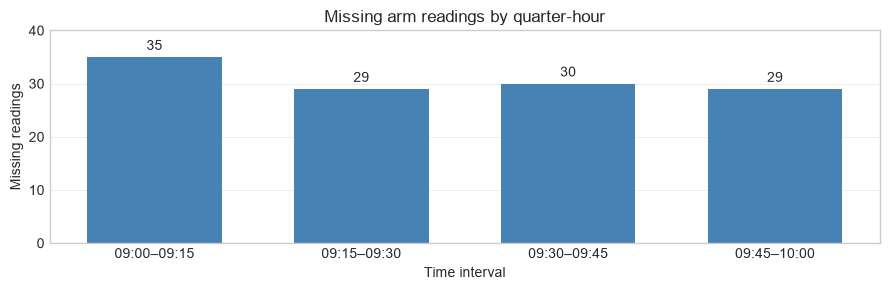

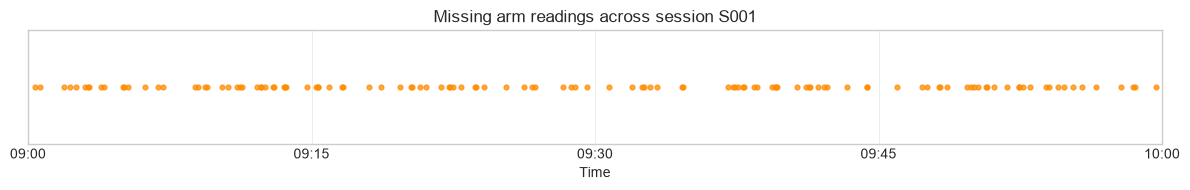

In [7]:

# Missing values in the arm sensor
arm = emf_df.set_index("timestamp")["Arm1_pT"].sort_index()
missing = arm.isna()

print(f"Missing arm readings: {missing.sum()} of {len(arm)} ({missing.mean():.2%})")

# 1. How many consecutive readings are missing in each gap?
# Each change between present and missing begins a new run.
run_id = missing.ne(missing.shift()).cumsum()
gap_lengths = missing[missing].groupby(run_id).size()

gap_counts = (
    gap_lengths.value_counts()
    .sort_index()
    .rename_axis("consecutive_missing_readings")
    .reset_index(name="number_of_gaps")
)

print("\nGap counts")
print(gap_counts.to_string(index=False))

# 2. How many readings are missing in each quarter of the hour?
quarters = missing.resample("15min")
quarter_table = pd.DataFrame({
    "Missing readings": quarters.sum(),
    "Missing (%)": 100 * quarters.mean(),
})

quarter_table.index = [
    f"{start:%H:%M}–{start + pd.Timedelta(minutes=15):%H:%M}"
    for start in quarter_table.index
]
quarter_table.index.name = "Time interval"

print("\nArm readings missing per quarter-hour")
print(quarter_table.to_string(float_format="{:.2f}".format))

# Plot the same counts shown in the table
fig, ax = plt.subplots(figsize=(9, 3))
bars = ax.bar(quarter_table.index, quarter_table["Missing readings"],
              color="steelblue", width=0.65)
ax.bar_label(bars, padding=3)
ax.set_ylim(0, quarter_table["Missing readings"].max() + 5)
ax.set_title("Missing arm readings by quarter-hour")
ax.set_xlabel("Time interval")
ax.set_ylabel("Missing readings")
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

# 3. When exactly were arm readings missing?
missing_times = arm.index[missing]

fig, ax = plt.subplots(figsize=(12, 2))

ax.scatter(missing_times, [0] * len(missing_times), s=12,
           color="darkorange", alpha=0.75)
ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.set_xlim(arm.index.min().floor("15min"), arm.index.max().ceil("15min"))
ax.xaxis.set_major_locator(mdates.MinuteLocator(byminute=[0, 15, 30, 45]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

ax.set_title(f"Missing arm readings across session {SESSION_ID}")
ax.set_xlabel("Time")
fig.tight_layout()
plt.show()

The arm channel was missing 123 of 3,600 readings (3.42%). Of these, 111 were isolated, and the remaining 12 occurred in six two-second gaps. Missing readings occurred throughout the hour, with similar counts across the four 15-minute intervals (29–35 per interval) and no obvious concentration in any single part of the session.

Readings outside the 1.5 × IQR limits
                Observed  Lower limit  Upper limit  Below  Above  Flagged  Flagged (%)
Channel                                                                               
Liver1_pT           3600        -6.99         7.08      5      3        8         0.22
Liver2_pT           3600        -8.47         8.55      7      5       12         0.33
Background1_pT      3600        -8.62         8.28      2      9       11         0.31
Arm1_pT             3477        -6.81         6.29      5    118      123         3.54
Chest1_pT           3600        -7.75         7.98     25      0       25         0.69
glucose_mg_dl         60        84.17       144.38      0      6        6        10.00


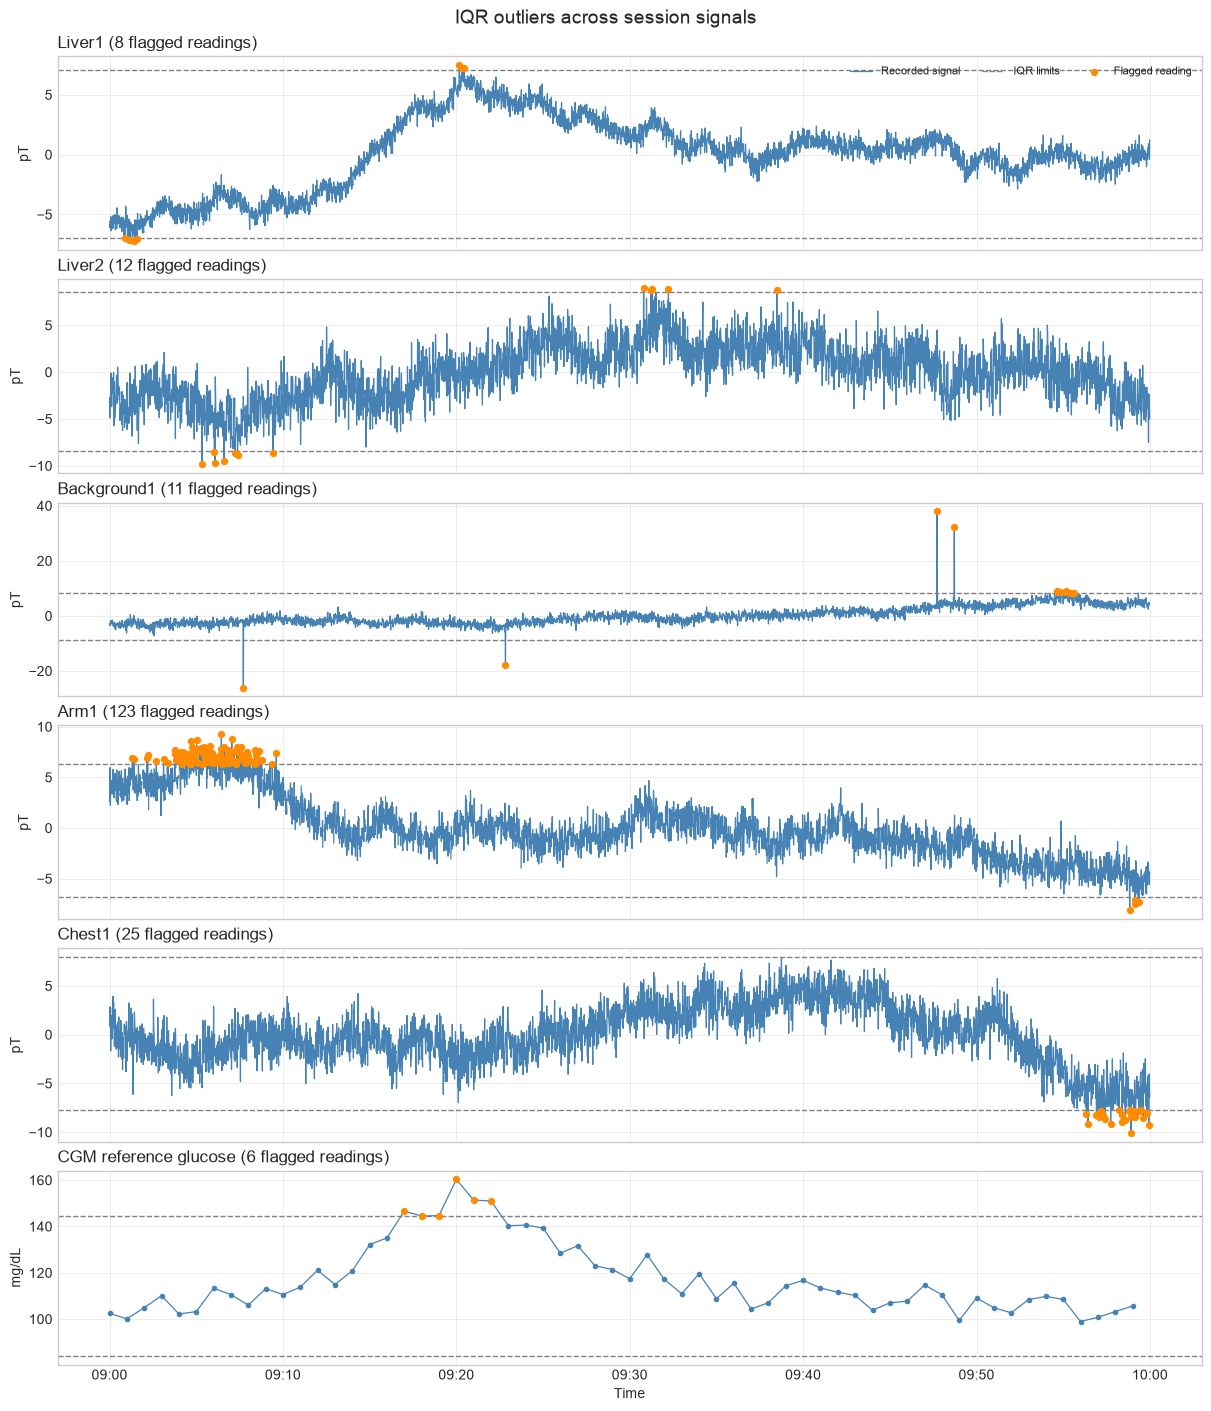

In [8]:
# Anomalies / outliers

IQR_MULTIPLIER = 1.5

# Keep EMF and glucose readings at their original sampling rates.
emf_signals = emf_df.set_index("timestamp").sort_index().filter(regex=r"_pT$")
glucose = cgm_df.set_index("timestamp").sort_index()["glucose_mg_dl"]

signals = dict(emf_signals.items())
signals["glucose_mg_dl"] = glucose

# 1. Calculate IQR limits and flag readings separately for each channel.
summary_rows = []
flagged_by_channel = {}

for name, readings in signals.items():
    observed = readings.dropna()
    q1 = observed.quantile(0.25)
    q3 = observed.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - IQR_MULTIPLIER * iqr
    upper = q3 + IQR_MULTIPLIER * iqr

    below = observed < lower
    above = observed > upper
    flagged = observed[below | above]
    flagged_by_channel[name] = flagged

    summary_rows.append({
        "Channel": name,
        "Observed": len(observed),
        "Lower limit": lower,
        "Upper limit": upper,
        "Below": below.sum(),
        "Above": above.sum(),
        "Flagged": len(flagged),
        "Flagged (%)": 100 * len(flagged) / len(observed),
    })

summary = pd.DataFrame(summary_rows).set_index("Channel")
print(f"Readings outside the {IQR_MULTIPLIER:g} × IQR limits")
print(summary.round(2).to_string())

# 2. Plot each channel and highlight its flagged readings.
fig, axes = plt.subplots(
    nrows=len(signals),
    ncols=1,
    figsize=(12, 14),
    sharex=True,
    constrained_layout=True,
)

for ax, (name, readings) in zip(axes, signals.items()):
    flagged = flagged_by_channel[name]
    is_glucose = name == "glucose_mg_dl"

    # Use the original series so missing arm readings appear as gaps.
    ax.plot(
        readings.index, readings,
        color="steelblue", linewidth=0.9,
        marker="o" if is_glucose else None, markersize=3,
        label="Recorded signal",
    )

    lower = summary.loc[name, "Lower limit"]
    upper = summary.loc[name, "Upper limit"]
    ax.axhline(lower, color="gray", linestyle="--", linewidth=1,
               label="IQR limits")
    ax.axhline(upper, color="gray", linestyle="--", linewidth=1)

    ax.scatter(
        flagged.index, flagged,
        color="darkorange", s=18, zorder=3,
        label="Flagged reading",
    )

    title = "CGM reference glucose" if is_glucose else name.removesuffix("_pT")
    ax.set_title(f"{title} ({len(flagged)} flagged readings)", loc="left")
    ax.set_ylabel("mg/dL" if is_glucose else "pT")

axes[0].legend(loc="upper right", ncol=3, fontsize=8)
axes[-1].xaxis.set_major_locator(mdates.MinuteLocator(byminute=range(0, 60, 10)))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
axes[-1].set_xlabel("Time")
fig.suptitle("IQR outliers across session signals", fontsize=14)
plt.show()
# Derive highlighted events using agreement between global and local screens.
MAD_WINDOW = "11s"
MAD_MIN_OBSERVED = 7
MAD_THRESHOLD = 8
background = emf_signals["Background1_pT"]
background_rolling = background.rolling(
    MAD_WINDOW, center=True, min_periods=MAD_MIN_OBSERVED
)
background_median = background_rolling.median()
background_mad = background_rolling.apply(
    lambda values: (values - values.median()).abs().median(), raw=False
)
background_scale = 1.4826 * background_mad
background_local_score = (
    (background - background_median).abs() / background_scale.where(background_scale.gt(0))
)
SPIKE_TIMES = background.index[
    background.index.isin(flagged_by_channel["Background1_pT"].index)
    & background_local_score.gt(MAD_THRESHOLD)
]
if len(SPIKE_TIMES) == 0:
    raise ValueError("No background events meet both screening criteria.")


All panels share the same time axis, and each has its own vertical scale. For each channel, the dashed lines show the IQR limits calculated from all available readings across the session, and the orange dots mark readings outside those limits. The liver panels illustrate the difference in scale. A 5 pT change takes up less vertical space in Liver 2 than in Liver 1. Liver 2 also fluctuates more from second to second, which makes its trace look denser.

Because the limits stay fixed throughout the session, several readings can cross the same threshold when a signal stays high or low for a while. This is visible in the arm channel early in the session and in the chest channel near the end. The six flagged CGM readings likewise occur around the peak of a single rise and fall. These flags mark parts of broader changes in signal level, and the recording alone leaves their causes uncertain.

Of the 11 background readings flagged by IQR, four stood out as isolated spikes. The zoomed plots show that each spike lasted one sample and that the next reading returned close to the surrounding level. Rolling MAD also flagged all four, making them the clearest examples of isolated outliers in this session.

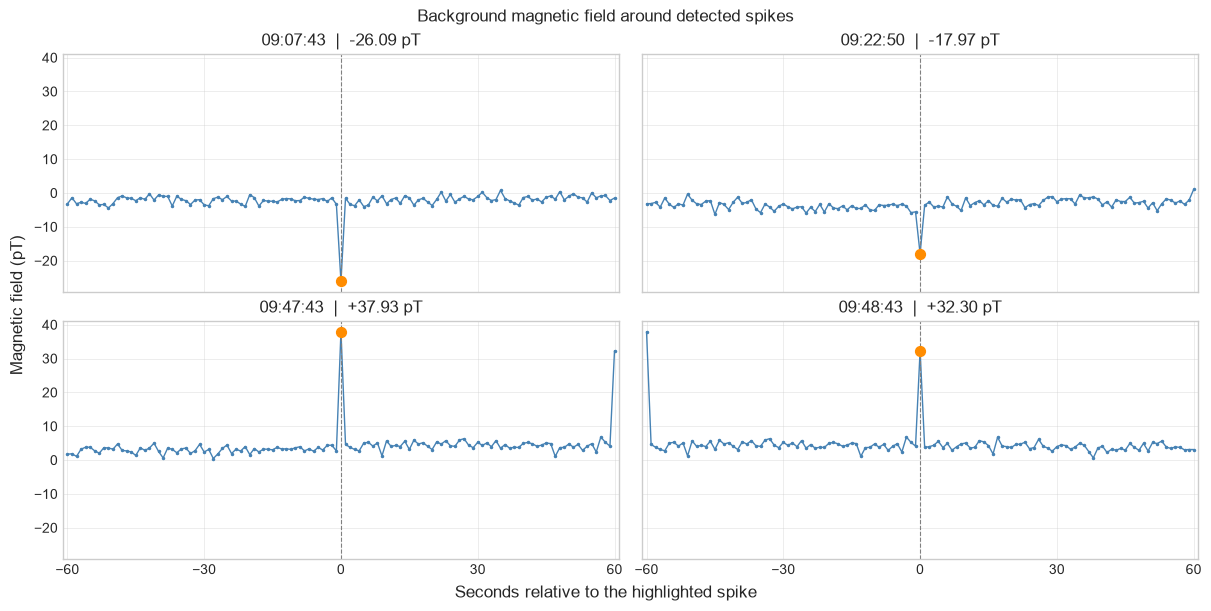

In [9]:
# Zoom in around each detected background spike.
background = emf_df.set_index("timestamp")["Background1_pT"].sort_index()

# Events identified by agreement between both screening methods
spike_times = SPIKE_TIMES

half_window = pd.Timedelta(minutes=1)
fig, axes = plt.subplots(
    (len(spike_times) + 1) // 2, 2, squeeze=False, figsize=(12, 3 * ((len(spike_times) + 1) // 2)), sharex=True, sharey=True,
    constrained_layout=True,
)

for ax, spike_time in zip(axes.flat, spike_times):
    window = background.loc[spike_time - half_window : spike_time + half_window]
    seconds = (window.index - spike_time).total_seconds()
    spike_value = background.loc[spike_time]

    ax.plot(seconds, window, color="steelblue", linewidth=1,
            marker=".", markersize=3)
    ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.scatter(0, spike_value, color="darkorange", s=50, zorder=3)

    ax.set_title(f"{spike_time:%H:%M:%S}  |  {spike_value:+.2f} pT")
    ax.set_xlim(-61, 61)
    ax.set_xticks([-60, -30, 0, 30, 60])

for unused_ax in list(axes.flat)[len(spike_times):]:
    unused_ax.set_visible(False)
fig.suptitle("Background magnetic field around detected spikes")
fig.supxlabel("Seconds relative to the highlighted spike")
fig.supylabel("Magnetic field (pT)")
plt.show()

The background signal was examined within a ±60-second window around each of the four largest spikes. Each deviation lasted a single sample, and the following reading returned close to the surrounding signal level. This pattern supports classifying the four events as isolated spikes.

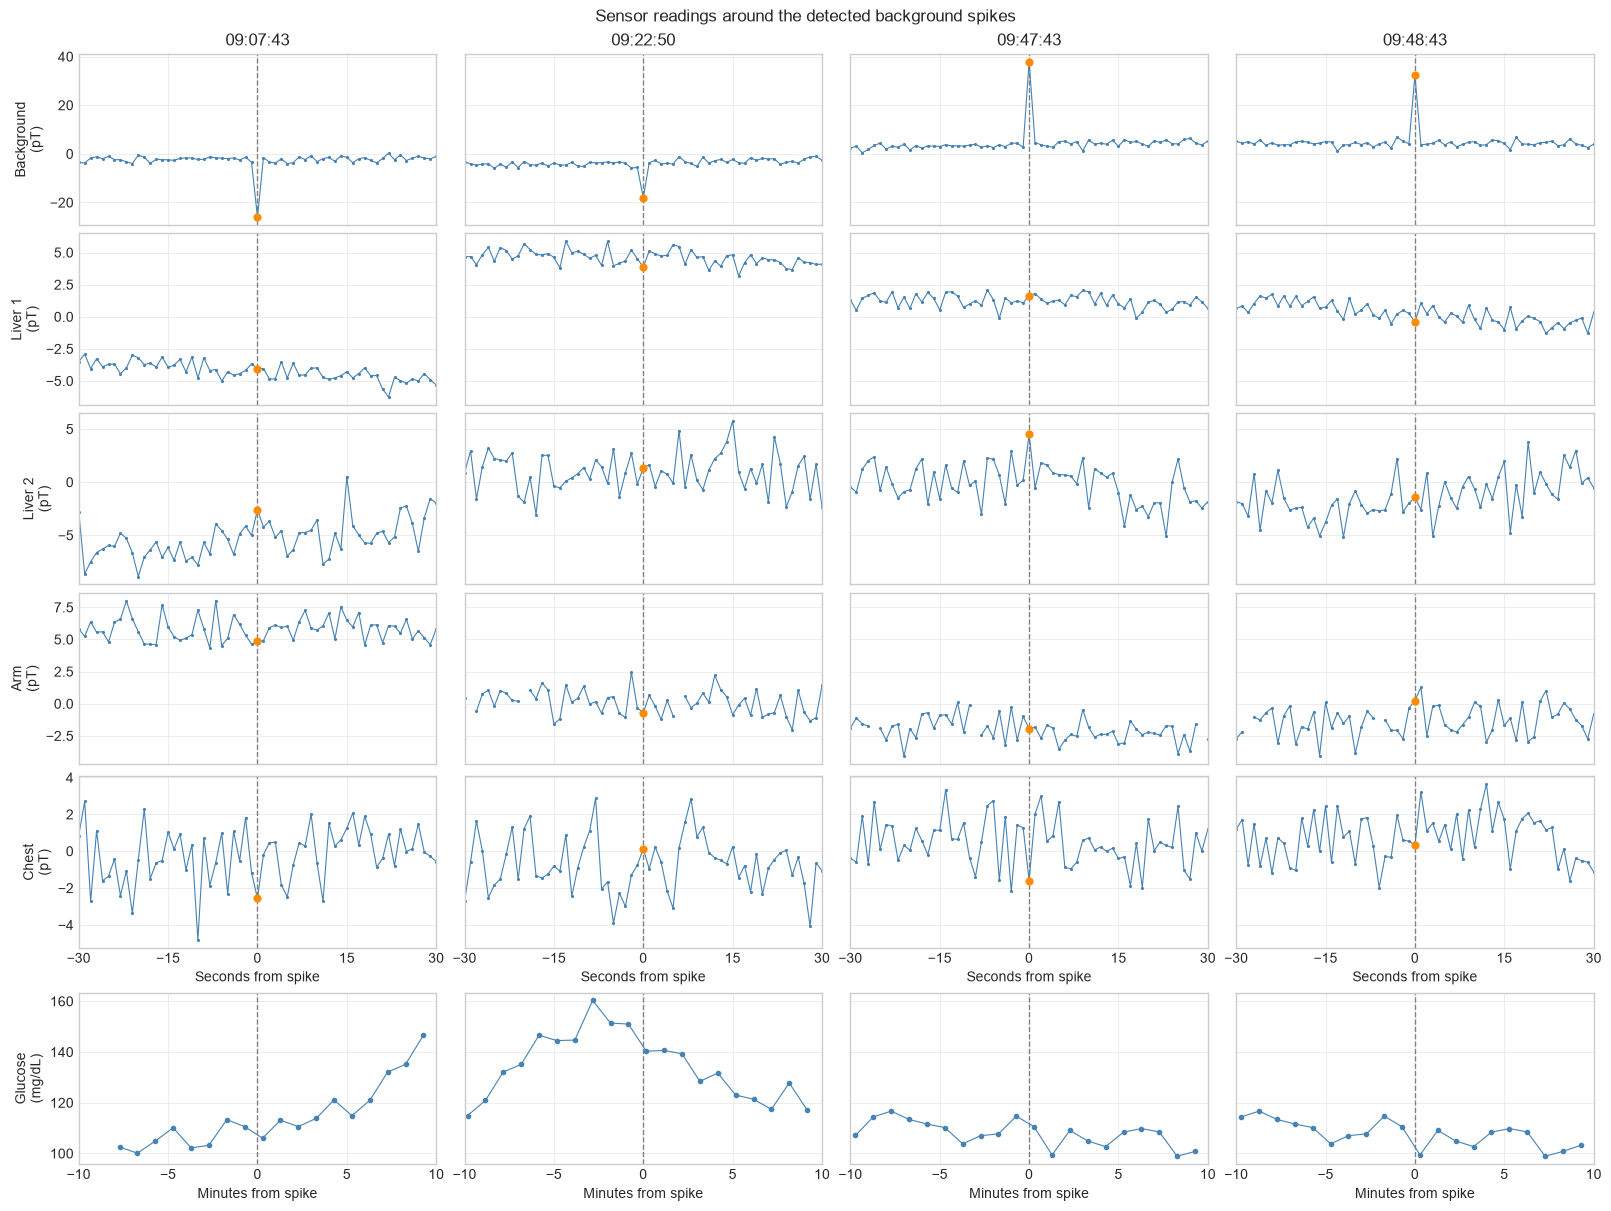

In [10]:

emf = emf_df.set_index("timestamp").sort_index()
glucose = cgm_df.set_index("timestamp").sort_index()["glucose_mg_dl"]

channels = {
    "Background": emf["Background1_pT"],
    "Liver 1": emf["Liver1_pT"],
    "Liver 2": emf["Liver2_pT"],
    "Arm": emf["Arm1_pT"],
    "Chest": emf["Chest1_pT"],
    "Glucose": glucose,
}

spike_times = SPIKE_TIMES

emf_half_window = pd.Timedelta(minutes=0.5)
cgm_half_window = pd.Timedelta(minutes=10)

fig, axes = plt.subplots(
    len(channels), len(spike_times),
    figsize=(4 * len(spike_times), 12), squeeze=False, sharey="row", constrained_layout=True,
)

for col, spike_time in enumerate(spike_times):
    axes[0, col].set_title(spike_time.strftime("%H:%M:%S"))

    for row, (name, readings) in enumerate(channels.items()):
        ax = axes[row, col]
        is_glucose = name == "Glucose"
        half_window = cgm_half_window if is_glucose else emf_half_window

        window = readings.loc[spike_time - half_window : spike_time + half_window]
        seconds = (window.index - spike_time).total_seconds()
        ax.axvline(0, color="gray", linestyle="--", linewidth=1)

        if is_glucose:
            ax.plot(seconds / 60, window, "o-", color="steelblue",
                    markersize=3, linewidth=0.8)
            ax.set_xlim(-10, 10)
            ax.set_xticks([-10, -5, 0, 5, 10])
            ax.set_xlabel("Minutes from spike")
        else:
            ax.plot(seconds, window, ".-", color="steelblue",
                    markersize=2.5, linewidth=0.8)

            value_at_spike = readings.get(spike_time)
            if pd.notna(value_at_spike):
                ax.scatter(0, value_at_spike, color="darkorange", s=24, zorder=3)

            ax.set_xlim(-30, 30)
            ax.set_xticks([-30, -15, 0, 15, 30])
            if name == "Chest":
                ax.set_xlabel("Seconds from spike")
            else:
                ax.tick_params(labelbottom=False)

        if col == 0:
            unit = "mg/dL" if is_glucose else "pT"
            ax.set_ylabel(f"{name}\n({unit})")

fig.suptitle("Sensor readings around the detected background spikes")
plt.show()

**Cross-channel comparison around background spikes**
The five EMF channels were aligned to the timestamps of the four background spikes and examined within ±30-second windows. The dashed line marks the event time, and orange markers identify the EMF readings at that instant. Visual inspection showed no consistent concurrent change in the other EMF channels across the four events.

The CGM trace was included to provide context for glucose trends before and after each event. Because CGM readings were recorded once per minute, they were displayed over a wider ±10-minute window. This sampling interval limits interpretation to minute-scale trends around the one-sample EMF spikes.

,Observed,Assessed,Flagged,Flagged (%)
Channel,,,,
Liver1_pT,3600,3598,3,0.08
Liver2_pT,3600,3598,3,0.08
Background1_pT,3600,3598,5,0.14
Arm1_pT,3477,3475,2,0.06
Chest1_pT,3600,3598,2,0.06


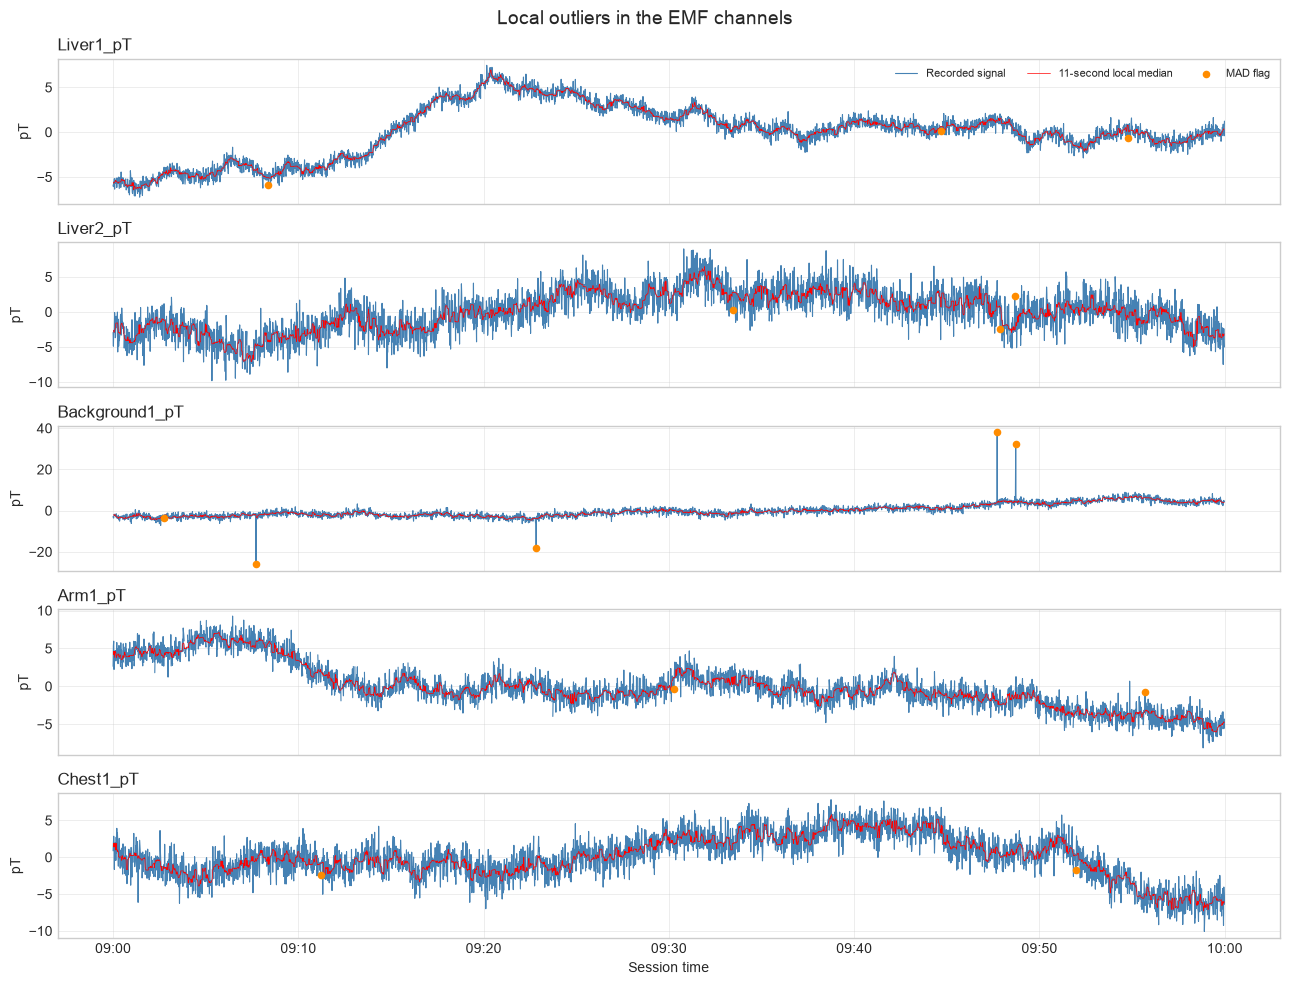

,Flagged background reading (pT)
timestamp,
2025-01-15 09:47:43,37.9280
2025-01-15 09:48:43,32.3030
2025-01-15 09:07:43,-26.0870
2025-01-15 09:22:50,-17.9680
2025-01-15 09:02:46,-3.8084


In [11]:
# Rolling MAD for the five EMF channels

emf_signals = emf_df.set_index("timestamp").sort_index().filter(regex=r"_pT$")

window = MAD_WINDOW
min_observed = MAD_MIN_OBSERVED
threshold = MAD_THRESHOLD

def median_absolute_deviation(values):
    median = values.median()
    return (values - median).abs().median()

summary_rows = []
mad_flagged_by_channel = {}

fig, axes = plt.subplots(
    len(emf_signals.columns), 1, figsize=(13, 10), sharex=True
)

for ax, (name, readings) in zip(axes, emf_signals.items()):
    # Compute the median and MAD from the same local window.
    rolling = readings.rolling(window, center=True, min_periods=min_observed)
    local_median = rolling.median()
    local_mad = rolling.apply(median_absolute_deviation, raw=False)

    # 1.4826 puts MAD on a standard-deviation scale for normally distributed data.
    local_scale = 1.4826 * local_mad
    assessed = readings.notna() & local_scale.gt(0)
    score = (readings - local_median).abs() / local_scale.where(assessed)
    flagged = readings[score > threshold]
    mad_flagged_by_channel[name] = flagged

    n_assessed = int(assessed.sum())
    summary_rows.append({
        "Channel": name,
        "Observed": readings.count(),
        "Assessed": n_assessed,
        "Flagged": len(flagged),
        "Flagged (%)": 100 * len(flagged) / n_assessed if n_assessed else float("nan"),
    })

    ax.plot(readings.index, readings, color="steelblue", linewidth=0.8,
            label="Recorded signal")
    ax.plot(local_median.index, local_median, color="red", linewidth=0.5,
            label=f"{pd.Timedelta(MAD_WINDOW).total_seconds():g}-second local median")
    ax.scatter(flagged.index, flagged, color="darkorange", s=20, zorder=3,
               label="MAD flag")
    ax.set_title(name, loc="left")
    ax.set_ylabel("pT")

axes[0].legend(loc="upper right", ncol=3, fontsize=8)
axes[-1].set_xlabel("Session time")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
fig.suptitle("Local outliers in the EMF channels", fontsize=14)
fig.tight_layout()

mad_summary = pd.DataFrame(summary_rows).set_index("Channel")
display(mad_summary.round(2))
plt.show()

# Inspect the largest flagged background readings first.
background_flags = mad_flagged_by_channel["Background1_pT"]
display(
    background_flags.sort_values(key=lambda values: values.abs(), ascending=False)
    .head(10)
    .rename("Flagged background reading (pT)")
    .to_frame()
)

**Local outlier assessment in the EMF channels**
The session-wide IQR screen flagged clusters of readings during sustained changes in the arm and chest signals. To identify shorter deviations, I compared each reading with the median of a centered 11-second window and scaled the difference by the variability within that window.

A rolling MAD score above 8 flagged 15 readings for review: five in the background channel, three in each liver channel, and two each in the arm and chest channels.

The background flags included all four previously identified spikes and one additional reading at 09:02:46 (−3.81 pT). This reading fell within the session-wide IQR limits but exceeded the local threshold, illustrating how the rolling MAD screen can detect a modest excursion during a relatively stable period.

**Data Quality Notes:**

_[What issues did you find? How severe are they?]_

The arm channel was missing 123 of 3,600 readings (3.42%). Of these, 111 were isolated and the remaining 12 occurred in six pairs. Missing readings were spread across the hour, with 29–35 per 15-minute interval. The gaps were brief and limited to the arm channel.

Four isolated outliers stood out in the background channel (−26.09 pT at 09:07:43, −17.97 pT at 09:22:50, +37.93 pT at 09:47:43, and +32.30 pT at 09:48:43). All four exceeded both the session-wide IQR limits and the local MAD threshold, and each returned close to its previous level at the next one-second reading. These spikes affected the recorded extremes. The other EMF channels showed no consistent simultaneous change across the four events. The CGM reference had no missing readings, but its one-minute sampling interval limited comparison at the timescale of the spikes.

The arm and chest channels also showed gradual declines. Their significance remains uncertain because this session alone provides no reference for the expected sensor drift.



---
## 3. Key Variable Distributions

Visualize the distributions of important variables.

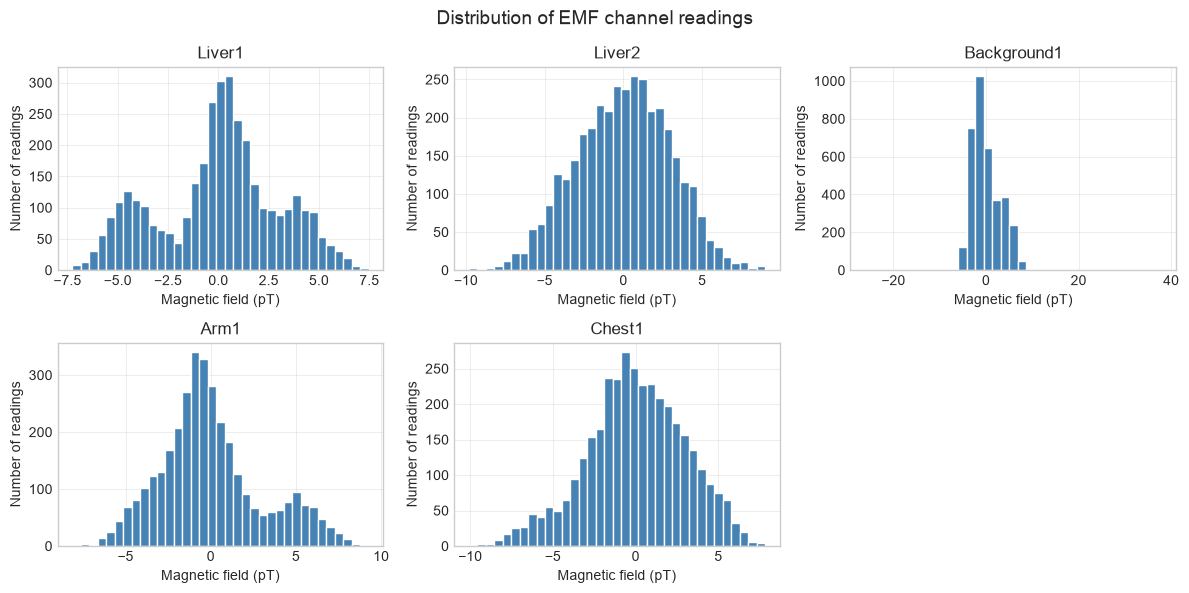

In [12]:
# EMF distributions

emf_channels = emf_df.filter(regex=r"_pT$")

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
axes = axes.ravel()

for ax, (channel, readings) in zip(axes, emf_channels.items()):
    ax.hist(readings.dropna(), bins=35, color="steelblue", edgecolor="white")
    ax.set_title(channel.removesuffix("_pT"))
    ax.set_xlabel("Magnetic field (pT)")
    ax.set_ylabel("Number of readings")

# The grid has six slots for five sensors.
fig.delaxes(axes[-1])
fig.suptitle("Distribution of EMF channel readings", fontsize=14)
fig.tight_layout()
plt.show()

**Distribution of EMF readings**
Each histogram shows how often a sensor recorded magnetic field values within a given range. At 1 Hz, the bar counts also reflect how much recorded time the signal spent in each range. The earlier time plots help identify when those values occurred.

Liver channels. Liver 1 shows a dominant peak near 0 pT and smaller peaks around −4.5 and +4 pT. This pattern is consistent with the gradual rise and fall visible in its time trace: readings were mostly negative early in the session, rose to positive values around 09:20, and later returned toward zero. Liver 2 shows one broader central peak and larger second-to-second fluctuations in its time trace. The earlier IQR panels used independent y-axis scales, so their tick values matter when comparing fluctuation amplitudes.

Arm and chest. The arm distribution has a main peak just below 0 pT and a smaller peak near +5 pT, consistent with the sustained higher readings early in the session. The chest distribution has one broad peak near 0 pT and a tail extending toward −10 pT. The time plot shows that the lowest chest readings occurred near the end of the session.

Background. Most background readings cluster within a narrow interval around zero. The four isolated spikes extend the observed range from −26.09 to +37.93 pT. Each contributes only one reading to its histogram bin, which explains why events that stand out clearly in the time plot are barely visible in the histogram.

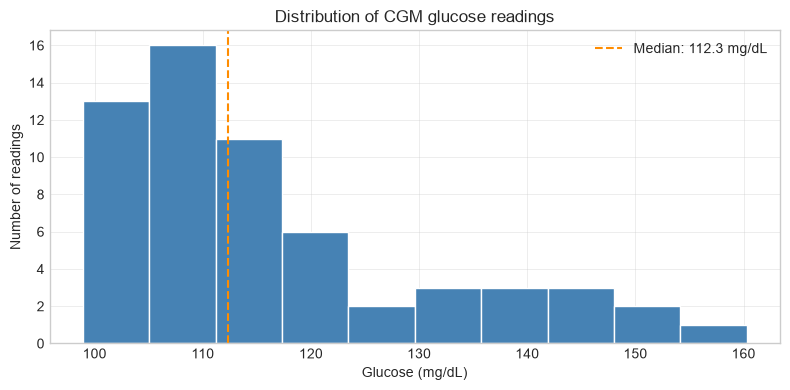

In [13]:
# CGM distributions
glucose = cgm_df["glucose_mg_dl"].dropna()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(glucose, bins=10, color="steelblue", edgecolor="white")

median_glucose = glucose.median()
ax.axvline(
    median_glucose,
    color="darkorange",
    linestyle="--",
    label=f"Median: {median_glucose:.1f} mg/dL",
)

ax.set_title("Distribution of CGM glucose readings")
ax.set_xlabel("Glucose (mg/dL)")
ax.set_ylabel("Number of readings")
ax.legend()
fig.tight_layout()
plt.show()

The glucose distribution is right-skewed. Most readings cluster around 100–120 mg/dL, with a median of 112.3 mg/dL. The right tail shows that higher readings occurred less often and extended as far as 160.3 mg/dL. The time plot adds context: the six highest readings occurred in consecutive minutes from 09:17 to 09:22, with the peak at 09:20. This places the upper end of the tail within a single rise and fall during the session

---
## 4. Preprocessing Recommendations

_[Based on what you found above, what preprocessing steps would you recommend before analysis?]_

Missing arm readings. The arm channel is missing 123 readings (3.42%), all in one- or two-second gaps. For descriptive statistics, use the available readings from each channel. If an analysis requires a continuous arm signal, fill short gaps by linear interpolation between the nearest observed values and flag each estimate (A Kalman smoother is worth considering if it gives lower reconstruction error on deliberately masked gaps of the same length).

Isolated background spikes- Four background readings exceeded both the session-wide IQR limits and the local MAD threshold. Each spike lasted one sample. Flag these readings and preserve the raw values. For analyses sensitive to extremes, compare results with and without the four spikes. If a continuous cleaned signal is needed, replace each flagged background value with the median of its neighboring readings.

Different sampling rates- EMF was recorded once per second and CGM once per minute. Use the original timestamps for plots. If the analysis requires paired observations, match each CGM reading to the median EMF value from each channel over the preceding 60 seconds. Record the number of observed samples in each window to identify incomplete coverage.

---
## 5. Optional: Time Series Exploration

Pick one EMF sensor and plot it alongside glucose over time for a single patient/session.

I selected the chest sensor for the time-series comparison with glucose because it had complete coverage throughout this session. It recorded all 3,600 readings, while the arm sensor was missing 123 (3.42%). The chest distribution was centered near zero, with both its mean and median rounding to 0.00 pT. Its interquartile range (3.93 pT) fell between those of Liver 1 (3.52 pT) and Liver 2 (4.25 pT).

Both liver channels also had means near zero, but Liver 1 had a higher median than Liver 2 (0.23 vs. 0.08 pT) and a narrower distribution across the middle 50% of readings. Without an independent reference, it was unclear which liver channel was more accurate. I therefore chose the chest sensor for its complete recording and zero-centered distribution.

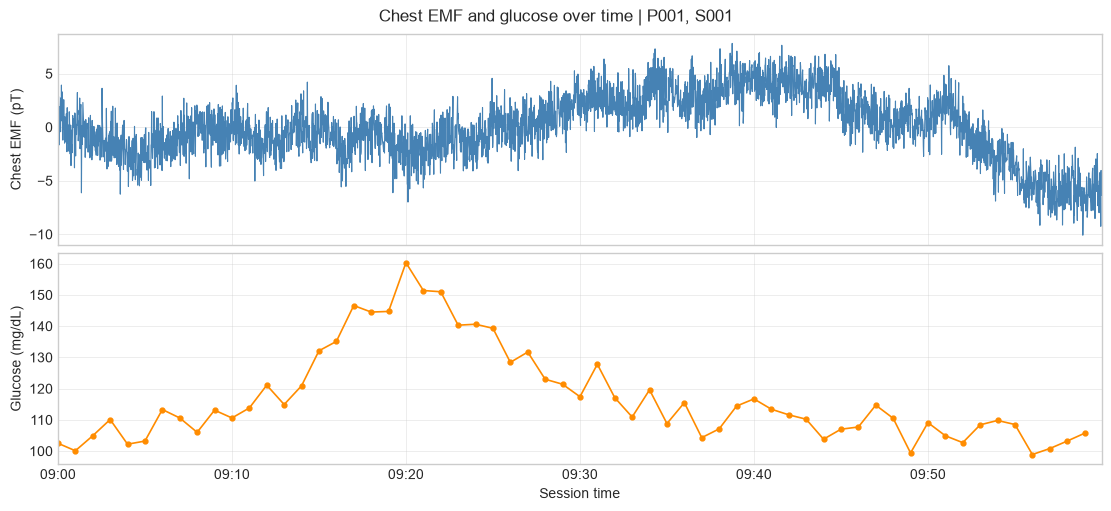

In [14]:

patient, session = PATIENT_ID, SESSION_ID

chest = emf_df.loc[
    (emf_df["patient_id"] == patient) & (emf_df["session_id"] == session),
    ["timestamp", "Chest1_pT"],
].sort_values("timestamp")

glucose = cgm_df.loc[
    (cgm_df["patient_id"] == patient) & (cgm_df["session_id"] == session),
    ["timestamp", "glucose_mg_dl"],
].sort_values("timestamp")

fig, (ax_chest, ax_glucose) = plt.subplots(
    2, 1, figsize=(11, 5), sharex=True, constrained_layout=True
)
fig.suptitle(f"Chest EMF and glucose over time | {patient}, {session}")

ax_chest.plot(chest["timestamp"], chest["Chest1_pT"],
              color="steelblue", linewidth=0.8)
ax_chest.set_ylabel("Chest EMF (pT)")

ax_glucose.plot(glucose["timestamp"], glucose["glucose_mg_dl"],
                color="darkorange", marker="o", markersize=3.5, linewidth=1.2)
ax_glucose.set_ylabel("Glucose (mg/dL)")
ax_glucose.set_xlabel("Session time")
ax_glucose.xaxis.set_major_locator(mdates.MinuteLocator(byminute=range(0, 60, 10)))
ax_glucose.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax_glucose.set_xlim(chest["timestamp"].min(), chest["timestamp"].max())

plt.show()

**Observations:**

_[What do you notice when comparing the two signals?]_

No consistent visual correspondence was evident between chest EMF and glucose during this session. Glucose peaked at approximately 160 mg/dL at 09:20, when chest EMF was near a local minimum. Over the following 20 minutes, glucose generally declined while chest EMF rose to its highest sustained levels.

**My Addition**

Comparison of the liver channels

I expected some shared variation because both sensors recorded over the same organ at the same time. The histograms showed several peaks for Liver 1 and one broader central peak for Liver 2. In the zoomed-in time traces, Liver 2 also appeared to fluctuate more from second to second than Liver 1. These observations raise a question about how closely the channels track one another across the full session. I would first examine the differences between simultaneous readings, then use PCA to explore how much of the variation follows a common pattern.